#Feature Engineering for London House-Price Prediction

Creating time-based, lagged, rolling, growth and inflation-adjusted features for forecasting London house prices.

All lagged and rolling variables are calculated separately for each London area and use only information available before the month being predicted to prevent data leakage.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Show all columns rather than hiding some
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
#Display floating-point numbers with commas and three decimal places

In [14]:
# adjust this file path as required depending on the local directory structure
file_path = '/clean_london_house_prices.csv'

df = pd.read_csv(file_path)

df.head()

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter
0,2001-01-01,barking and dagenham,82343,E09000002,215.000,"1,771.000",1,66.179,2.708,-0.633,6.000,2001,1,1
1,2001-02-01,barking and dagenham,83266,E09000002,238.000,"1,600.000",1,66.522,2.679,0.519,5.812,2001,2,1
2,2001-03-01,barking and dagenham,84058,E09000002,274.000,"1,759.000",1,66.601,2.258,0.118,5.750,2001,3,1
3,2001-04-01,barking and dagenham,83965,E09000002,241.000,"1,643.000",1,66.954,1.773,0.530,5.533,2001,4,2
4,2001-05-01,barking and dagenham,85124,E09000002,283.000,"1,809.000",1,67.375,2.049,0.630,5.323,2001,5,2


In [15]:
print("Dataset shape:", df.shape)

display(df.head())

df.info()

Dataset shape: (7375, 14)


,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter
0,2001-01-01,barking and dagenham,82343,E09000002,215.000,"1,771.000",1,66.179,2.708,-0.633,6.000,2001,1,1
1,2001-02-01,barking and dagenham,83266,E09000002,238.000,"1,600.000",1,66.522,2.679,0.519,5.812,2001,2,1
2,2001-03-01,barking and dagenham,84058,E09000002,274.000,"1,759.000",1,66.601,2.258,0.118,5.750,2001,3,1
3,2001-04-01,barking and dagenham,83965,E09000002,241.000,"1,643.000",1,66.954,1.773,0.530,5.533,2001,4,2
4,2001-05-01,barking and dagenham,85124,E09000002,283.000,"1,809.000",1,67.375,2.049,0.630,5.323,2001,5,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7375 entries, 0 to 7374
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   7375 non-null   object 
 1   area                   7375 non-null   object 
 2   average_price          7375 non-null   int64  
 3   code                   7375 non-null   object 
 4   houses_sold            7375 non-null   float64
 5   no_of_crimes           7375 non-null   float64
 6   borough_flag           7375 non-null   int64  
 7   cpi_index_2015_100     7375 non-null   float64
 8   cpi_yoy_pct            7375 non-null   float64
 9   cpi_mom_pct            7375 non-null   float64
 10  bank_rate_monthly_avg  7375 non-null   float64
 11  year                   7375 non-null   int64  
 12  month                  7375 non-null   int64  
 13  quarter                7375 non-null   int64  
dtypes: float64(6), int64(5), object(3)
memory usage: 806.8+ 

In [16]:
print(df.columns.tolist())

['date', 'area', 'average_price', 'code', 'houses_sold', 'no_of_crimes', 'borough_flag', 'cpi_index_2015_100', 'cpi_yoy_pct', 'cpi_mom_pct', 'bank_rate_monthly_avg', 'year', 'month', 'quarter']


In [17]:
df['date'] = pd.to_datetime(df['date'])

df = (
    df.sort_values(['area', 'date'])
      .reset_index(drop=True)
)

print("Start date:", df['date'].min())
print("End date:", df['date'].max())
print("Number of areas:", df['area'].nunique())
print("Duplicate area-month rows:", df.duplicated(['area', 'date']).sum())

Start date: 2001-01-01 00:00:00
End date: 2019-11-01 00:00:00
Number of areas: 33
Duplicate area-month rows: 0


In [ ]:
#history available for each area
area_date_check = (
    df.groupby('area')['date']
      .agg(['min', 'max', 'count'])
      .sort_values('count')
)

area_date_check.head(10)

,min,max,count
area,,,
city of london,2001-01-01,2010-03-01,111
barking and dagenham,2001-01-01,2019-11-01,227
bexley,2001-01-01,2019-11-01,227
barnet,2001-01-01,2019-11-01,227
brent,2001-01-01,2019-11-01,227
bromley,2001-01-01,2019-11-01,227
camden,2001-01-01,2019-11-01,227
croydon,2001-01-01,2019-11-01,227
ealing,2001-01-01,2019-11-01,227


In [ ]:
#Checking monthly gaps
df['month_gap'] = (
    df.groupby('area')['date']
      .diff()
      .dt.days
)
#calculates the number of days between consecutive observations for the same area

df['month_gap'].value_counts().sort_index().head(20)
#shows in days

,count
month_gap,
28.000,488
29.000,130
30.000,2436
31.000,4288


In [20]:
unusual_gaps = df[
    df['month_gap'].notna() &
    ~df['month_gap'].between(28, 31)
]

print("Unusual monthly gaps:", len(unusual_gaps))

display(
    unusual_gaps[
        ['area', 'date', 'month_gap']
    ].head(20)
)


Unusual monthly gaps: 0


,area,date,month_gap


In [ ]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter

df['month_name'] = df['date'].dt.month_name().str[:3]
df['time_index'] = (
    (df['year'] - df['year'].min()) * 12
    + df['month']
)
#The time index provides a continuous representation of the long-term temporal trend, whereas year alone changes only annually

In [22]:
df[
    [
        'date',
        'year',
        'month',
        'quarter',
        'month_name',
        'time_index'
    ]
].head()

,date,year,month,quarter,month_name,time_index
0,2001-01-01,2001,1,1,Jan,1
1,2001-02-01,2001,2,1,Feb,2
2,2001-03-01,2001,3,1,Mar,3
3,2001-04-01,2001,4,2,Apr,4
4,2001-05-01,2001,5,2,May,5


In [ ]:
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)

df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

df[
    ['month', 'month_name', 'month_sin', 'month_cos']
].drop_duplicates().sort_values('month')

,month,month_name,month_sin,month_cos
0,1,Jan,0.500,0.866
1,2,Feb,0.866,0.500
2,3,Mar,1.000,0.000
3,4,Apr,0.866,-0.500
4,5,May,0.500,-0.866
5,6,Jun,0.000,-1.000
6,7,Jul,-0.500,-0.866
7,8,Aug,-0.866,-0.500
8,9,Sep,-1.000,-0.000
9,10,Oct,-0.866,0.500


 used sine and cosine month encoding because calendar months are cyclical. Standard numeric encoding would incorrectly imply that December is much further from January than February is. Cyclical encoding preserves the seasonal relationship.

In [24]:
price_group = df.groupby('area')['average_price']

df['price_lag_1'] = price_group.shift(1)
df['price_lag_3'] = price_group.shift(3)
df['price_lag_6'] = price_group.shift(6)
df['price_lag_12'] = price_group.shift(12)
sample_area = df['area'].dropna().iloc[0]

display(
    df[df['area'] == sample_area][
        [
            'date',
            'area',
            'average_price',
            'price_lag_1',
            'price_lag_3',
            'price_lag_6',
            'price_lag_12'
        ]
    ].head(15)
)

,date,area,average_price,price_lag_1,price_lag_3,price_lag_6,price_lag_12
0,2001-01-01,barking and dagenham,82343,NaN,NaN,NaN,NaN
1,2001-02-01,barking and dagenham,83266,"82,343.000",NaN,NaN,NaN
2,2001-03-01,barking and dagenham,84058,"83,266.000",NaN,NaN,NaN
3,2001-04-01,barking and dagenham,83965,"84,058.000","82,343.000",NaN,NaN
4,2001-05-01,barking and dagenham,85124,"83,965.000","83,266.000",NaN,NaN
5,2001-06-01,barking and dagenham,86732,"85,124.000","84,058.000",NaN,NaN
6,2001-07-01,barking and dagenham,89194,"86,732.000","83,965.000","82,343.000",NaN
7,2001-08-01,barking and dagenham,90462,"89,194.000","85,124.000","83,266.000",NaN
8,2001-09-01,barking and dagenham,92610,"90,462.000","86,732.000","84,058.000",NaN
9,2001-10-01,barking and dagenham,93584,"92,610.000","89,194.000","83,965.000",NaN


In [25]:
lag_check = df[
    [
        'area',
        'date',
        'average_price',
        'price_lag_1'
    ]
].copy()

lag_check['previous_area'] = lag_check['area'].shift(1)

boundary_rows = lag_check[
    lag_check['area'] != lag_check['previous_area']
]

display(boundary_rows.head(10))

,area,date,average_price,price_lag_1,previous_area
0,barking and dagenham,2001-01-01,82343,NaN,None
227,barnet,2001-01-01,175475,NaN,barking and dagenham
454,bexley,2001-01-01,111194,NaN,barnet
681,brent,2001-01-01,148306,NaN,bexley
908,bromley,2001-01-01,153615,NaN,brent
1135,camden,2001-01-01,265515,NaN,bromley
1362,city of london,2001-01-01,284262,NaN,camden
1473,croydon,2001-01-01,127511,NaN,city of london
1700,ealing,2001-01-01,159483,NaN,croydon
1927,enfield,2001-01-01,125851,NaN,ealing


In [26]:
first_rows = df.groupby('area').head(1)

print(
    "First area rows with non-missing lag:",
    first_rows['price_lag_1'].notna().sum()
)

First area rows with non-missing lag: 0


In [27]:
sales_group = df.groupby('area')['houses_sold']

df['houses_sold_lag_1'] = sales_group.shift(1)
df['houses_sold_lag_3'] = sales_group.shift(3)
df['houses_sold_lag_12'] = sales_group.shift(12)

In [28]:
if 'no_of_crimes' in df.columns:
    crime_group = df.groupby('area')['no_of_crimes']

    df['crime_lag_1'] = crime_group.shift(1)
    df['crime_lag_12'] = crime_group.shift(12)

explored historical crime features during engineering, but  did not include them in the final feature sets because the crime variable had greater data-quality and completeness concerns, particularly in earlier periods and preferred more consistently measured predictors.

In [ ]:
#rolling price features
df['price_rolling_mean_3'] = (
    df.groupby('area')['average_price']
      .transform(
          lambda x: x.shift(1).rolling(
              window=3,
              min_periods=3
          ).mean()
      )
)

#average price during previous 6 months
df['price_rolling_mean_6'] = (
    df.groupby('area')['average_price']
      .transform(
          lambda x: x.shift(1).rolling(
              window=6,
              min_periods=6
          ).mean()
      )
)

df['price_rolling_mean_12'] = (
    df.groupby('area')['average_price']
      .transform(
          lambda x: x.shift(1).rolling(
              window=12,
              min_periods=12
          ).mean()
      )
)

Rolling averages provide a smoothed representation of recent market conditions and are less sensitive to a single unusual month than an individual lag.

shifted the series by one observation before calculating rolling statistics. This ensures that the current target month is excluded from the predictor and prevents target leakage.

In [ ]:
#rolling price volatility standard deviations

#3 months short-term volatility
df['price_rolling_std_3'] = (
    df.groupby('area')['average_price']
      .transform(
          lambda x: x.shift(1).rolling(
              window=3,
              min_periods=3
          ).std()
      )
)

#longer annual variation 
df['price_rolling_std_12'] = (
    df.groupby('area')['average_price']
      .transform(
          lambda x: x.shift(1).rolling(
              window=12,
              min_periods=12
          ).std()
      )
)

In [31]:
#rolling houses-sold features
df['houses_sold_rolling_mean_3'] = (
    df.groupby('area')['houses_sold']
      .transform(
          lambda x: x.shift(1).rolling(
              window=3,
              min_periods=3
          ).mean()
      )
)

df['houses_sold_rolling_mean_12'] = (
    df.groupby('area')['houses_sold']
      .transform(
          lambda x: x.shift(1).rolling(
              window=12,
              min_periods=12
          ).mean()
      )
)

In [32]:
#house-price growth features

#Previous-month growth, three month growth, twelve months growth
df['price_mom_growth_pct'] = (
    df.groupby('area')['average_price']
      .pct_change(periods=1) * 100
)
df['price_3m_growth_pct'] = (
    df.groupby('area')['average_price']
      .pct_change(periods=3) * 100
)
df['price_yoy_growth_pct'] = (
    df.groupby('area')['average_price']
      .pct_change(periods=12) * 100
)

#lagged growth features in predictive models
df['price_mom_growth_lag_1'] = (
    df.groupby('area')['price_mom_growth_pct']
      .shift(1)
)

df['price_3m_growth_lag_1'] = (
    df.groupby('area')['price_3m_growth_pct']
      .shift(1)
)

df['price_yoy_growth_lag_1'] = (
    df.groupby('area')['price_yoy_growth_pct']
      .shift(1)
)

In [33]:
#houses-sold growth features

df['houses_sold_mom_growth_pct'] = (
    df.groupby('area')['houses_sold']
      .pct_change(periods=1) * 100
)

df['houses_sold_yoy_growth_pct'] = (
    df.groupby('area')['houses_sold']
      .pct_change(periods=12) * 100
)

df['houses_sold_mom_growth_lag_1'] = (
    df.groupby('area')['houses_sold_mom_growth_pct']
      .shift(1)
)

df['houses_sold_yoy_growth_lag_1'] = (
    df.groupby('area')['houses_sold_yoy_growth_pct']
      .shift(1)
)

In [ ]:
#replace infinity
df = df.replace([np.inf, -np.inf], np.nan)

growth_columns = [
    col for col in df.columns
    if 'growth' in col
]

df[growth_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
price_mom_growth_pct,"7,342.000",0.527,1.833,-30.298,-0.389,0.573,1.489,31.290
price_3m_growth_pct,"7,276.000",1.634,3.923,-29.957,-0.425,1.698,3.779,57.613
price_yoy_growth_pct,"6,979.000",6.611,8.667,-27.611,1.454,6.357,12.199,43.343
price_mom_growth_lag_1,"7,309.000",0.530,1.829,-30.298,-0.385,0.577,1.492,31.290
price_3m_growth_lag_1,"7,243.000",1.640,3.918,-29.957,-0.418,1.703,3.793,57.613
price_yoy_growth_lag_1,"6,946.000",6.643,8.667,-27.611,1.486,6.399,12.240,43.343
houses_sold_mom_growth_pct,"7,342.000",1.981,22.295,-83.673,-11.244,0.443,12.727,480.000
houses_sold_yoy_growth_pct,"6,979.000",1.783,35.429,-90.909,-19.285,-1.207,17.973,450.000
houses_sold_mom_growth_lag_1,"7,309.000",1.997,22.288,-83.673,-11.241,0.508,12.755,480.000
houses_sold_yoy_growth_lag_1,"6,946.000",1.860,35.452,-90.909,-19.184,-1.102,18.027,450.000


In [ ]:
#Inflation-adjusted price
df['real_price_2015'] = (
    df['average_price']
    * 100
    / df['cpi_index_2015_100']
)

adjusted nominal house prices using CPI with 2015 equal to 100, allowing historical prices to be expressed in comparable 2015 purchasing-power terms.

In [36]:
df[
    [
        'date',
        'area',
        'average_price',
        'cpi_index_2015_100',
        'real_price_2015'
    ]
].head()

,date,area,average_price,cpi_index_2015_100,real_price_2015
0,2001-01-01,barking and dagenham,82343,66.179,"124,424.339"
1,2001-02-01,barking and dagenham,83266,66.522,"125,170.008"
2,2001-03-01,barking and dagenham,84058,66.601,"126,211.773"
3,2001-04-01,barking and dagenham,83965,66.954,"125,407.529"
4,2001-05-01,barking and dagenham,85124,67.375,"126,343.034"


In [37]:
real_price_group = df.groupby('area')['real_price_2015']

df['real_price_lag_1'] = real_price_group.shift(1)
df['real_price_lag_12'] = real_price_group.shift(12)

df['real_price_rolling_mean_12'] = (
    df.groupby('area')['real_price_2015']
      .transform(
          lambda x: x.shift(1).rolling(
              window=12,
              min_periods=12
          ).mean()
      )
)

In [38]:
df['cpi_lag_1'] = (
    df.groupby('area')['cpi_index_2015_100']
      .shift(1)
)

df['cpi_lag_3'] = (
    df.groupby('area')['cpi_index_2015_100']
      .shift(3)
)

df['cpi_lag_12'] = (
    df.groupby('area')['cpi_index_2015_100']
      .shift(12)
)

use lagged CPI because macroeconomic conditions may influence housing with delays

not current CPI because use information available before the target period.That reduces potential look-ahead bias.

In [39]:
df['bank_rate_lag_1'] = (
    df.groupby('area')['bank_rate_monthly_avg']
      .shift(1)
)

df['bank_rate_lag_3'] = (
    df.groupby('area')['bank_rate_monthly_avg']
      .shift(3)
)

df['bank_rate_lag_12'] = (
    df.groupby('area')['bank_rate_monthly_avg']
      .shift(12)
)

In [ ]:
#1 month ago and 12 months ago
df['bank_rate_change_1m'] = (
    df.groupby('area')['bank_rate_monthly_avg']
      .diff(1)
)

df['bank_rate_change_12m'] = (
    df.groupby('area')['bank_rate_monthly_avg']
      .diff(12)
)

In [41]:
df['bank_rate_change_1m_lag_1'] = (
    df.groupby('area')['bank_rate_change_1m']
      .shift(1)
)

df['bank_rate_change_12m_lag_1'] = (
    df.groupby('area')['bank_rate_change_12m']
      .shift(1)
)

In [ ]:
df['post_2008'] = (df['year'] >= 2009).astype(int) #indicating post-financial-crisis period
df['pandemic_2020'] = (df['year'] == 2020).astype(int) #return 1 or 0

In [43]:
engineered_columns = [
    'year',
    'month',
    'quarter',
    'time_index',
    'month_sin',
    'month_cos',

    'price_lag_1',
    'price_lag_3',
    'price_lag_6',
    'price_lag_12',

    'price_rolling_mean_3',
    'price_rolling_mean_6',
    'price_rolling_mean_12',
    'price_rolling_std_3',
    'price_rolling_std_12',

    'houses_sold_lag_1',
    'houses_sold_lag_3',
    'houses_sold_lag_12',
    'houses_sold_rolling_mean_3',
    'houses_sold_rolling_mean_12',

    'price_mom_growth_lag_1',
    'price_3m_growth_lag_1',
    'price_yoy_growth_lag_1',

    'real_price_2015',
    'real_price_lag_1',
    'real_price_lag_12',

    'cpi_lag_1',
    'cpi_lag_3',
    'cpi_lag_12',

    'bank_rate_lag_1',
    'bank_rate_lag_3',
    'bank_rate_lag_12',
    'bank_rate_change_1m_lag_1',

    'post_2008'
]

display(df[engineered_columns].head(15))

,year,month,quarter,time_index,month_sin,month_cos,price_lag_1,price_lag_3,price_lag_6,price_lag_12,price_rolling_mean_3,price_rolling_mean_6,price_rolling_mean_12,price_rolling_std_3,price_rolling_std_12,houses_sold_lag_1,houses_sold_lag_3,houses_sold_lag_12,houses_sold_rolling_mean_3,houses_sold_rolling_mean_12,price_mom_growth_lag_1,price_3m_growth_lag_1,price_yoy_growth_lag_1,real_price_2015,real_price_lag_1,real_price_lag_12,cpi_lag_1,cpi_lag_3,cpi_lag_12,bank_rate_lag_1,bank_rate_lag_3,bank_rate_lag_12,bank_rate_change_1m_lag_1,post_2008
0,2001,1,1,1,0.500,0.866,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"124,424.339",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2001,2,1,2,0.866,0.500,"82,343.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,215.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"125,170.008","124,424.339",NaN,66.179,NaN,NaN,6.000,NaN,NaN,NaN,0
2,2001,3,1,3,1.000,0.000,"83,266.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,238.000,NaN,NaN,NaN,NaN,1.121,NaN,NaN,"126,211.773","125,170.008",NaN,66.522,NaN,NaN,5.812,NaN,NaN,-0.188,0
3,2001,4,2,4,0.866,-0.500,"84,058.000","82,343.000",NaN,NaN,"83,222.333",NaN,NaN,858.333,NaN,274.000,215.000,NaN,242.333,NaN,0.951,NaN,NaN,"125,407.529","126,211.773",NaN,66.601,66.179,NaN,5.750,6.000,NaN,-0.062,0
4,2001,5,2,5,0.500,-0.866,"83,965.000","83,266.000",NaN,NaN,"83,763.000",NaN,NaN,432.919,NaN,241.000,238.000,NaN,251.000,NaN,-0.111,1.970,NaN,"126,343.034","125,407.529",NaN,66.954,66.522,NaN,5.533,5.812,NaN,-0.217,0
5,2001,6,2,6,0.000,-1.000,"85,124.000","84,058.000",NaN,NaN,"84,382.333",NaN,NaN,643.983,NaN,283.000,274.000,NaN,266.000,NaN,1.380,2.231,NaN,"128,579.980","126,343.034",NaN,67.375,66.601,NaN,5.323,5.750,NaN,-0.211,0
6,2001,7,3,7,-0.500,-0.866,"86,732.000","83,965.000","82,343.000",NaN,"85,273.667","84,248.000",NaN,"1,389.558",NaN,292.000,241.000,NaN,272.000,NaN,1.889,3.181,NaN,"133,061.523","128,579.980",NaN,67.454,66.954,NaN,5.250,5.533,NaN,-0.073,0
7,2001,8,3,8,-0.866,-0.500,"89,194.000","85,124.000","83,266.000",NaN,"87,016.667","85,389.833",NaN,"2,049.878",NaN,289.000,283.000,NaN,288.000,NaN,2.839,6.228,NaN,"134,422.306","133,061.523",NaN,67.032,67.375,NaN,5.250,5.323,NaN,0.000,0
8,2001,9,3,9,-1.000,-0.000,"90,462.000","86,732.000","84,058.000",NaN,"88,796.000","86,589.167",NaN,"1,896.583",NaN,321.000,292.000,NaN,300.667,NaN,1.422,6.271,NaN,"137,134.642","134,422.306",NaN,67.297,67.454,NaN,5.008,5.250,NaN,-0.242,0
9,2001,10,4,10,-0.866,0.500,"92,610.000","89,194.000","83,965.000",NaN,"90,755.333","88,014.500",NaN,"1,726.788",NaN,251.000,289.000,NaN,287.000,NaN,2.374,6.777,NaN,"138,818.762","137,134.642",NaN,67.532,67.032,NaN,4.892,5.250,NaN,-0.116,0


In [44]:
feature_missing = (
    df[engineered_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(feature_missing)

,0
price_yoy_growth_lag_1,429
price_lag_12,396
bank_rate_lag_12,396
real_price_lag_12,396
price_rolling_std_12,396
houses_sold_lag_12,396
cpi_lag_12,396
price_rolling_mean_12,396
houses_sold_rolling_mean_12,396
price_rolling_mean_6,198


Missing values at the beginning of each borough's series are expected rather than data-quality failures. A twelve-month lag cannot be calculated until sufficient historical observations exist.

In [45]:
sample_area = 'barking and dagenham'

validation_sample = df[
    df['area'] == sample_area
][
    [
        'date',
        'average_price',
        'price_lag_1',
        'price_lag_3',
        'price_lag_12',
        'price_rolling_mean_3',
        'price_rolling_mean_12',
        'price_yoy_growth_lag_1'
    ]
].head(20)

display(validation_sample)

,date,average_price,price_lag_1,price_lag_3,price_lag_12,price_rolling_mean_3,price_rolling_mean_12,price_yoy_growth_lag_1
0,2001-01-01,82343,NaN,NaN,NaN,NaN,NaN,NaN
1,2001-02-01,83266,"82,343.000",NaN,NaN,NaN,NaN,NaN
2,2001-03-01,84058,"83,266.000",NaN,NaN,NaN,NaN,NaN
3,2001-04-01,83965,"84,058.000","82,343.000",NaN,"83,222.333",NaN,NaN
4,2001-05-01,85124,"83,965.000","83,266.000",NaN,"83,763.000",NaN,NaN
5,2001-06-01,86732,"85,124.000","84,058.000",NaN,"84,382.333",NaN,NaN
6,2001-07-01,89194,"86,732.000","83,965.000",NaN,"85,273.667",NaN,NaN
7,2001-08-01,90462,"89,194.000","85,124.000",NaN,"87,016.667",NaN,NaN
8,2001-09-01,92610,"90,462.000","86,732.000",NaN,"88,796.000",NaN,NaN
9,2001-10-01,93584,"92,610.000","89,194.000",NaN,"90,755.333",NaN,NaN


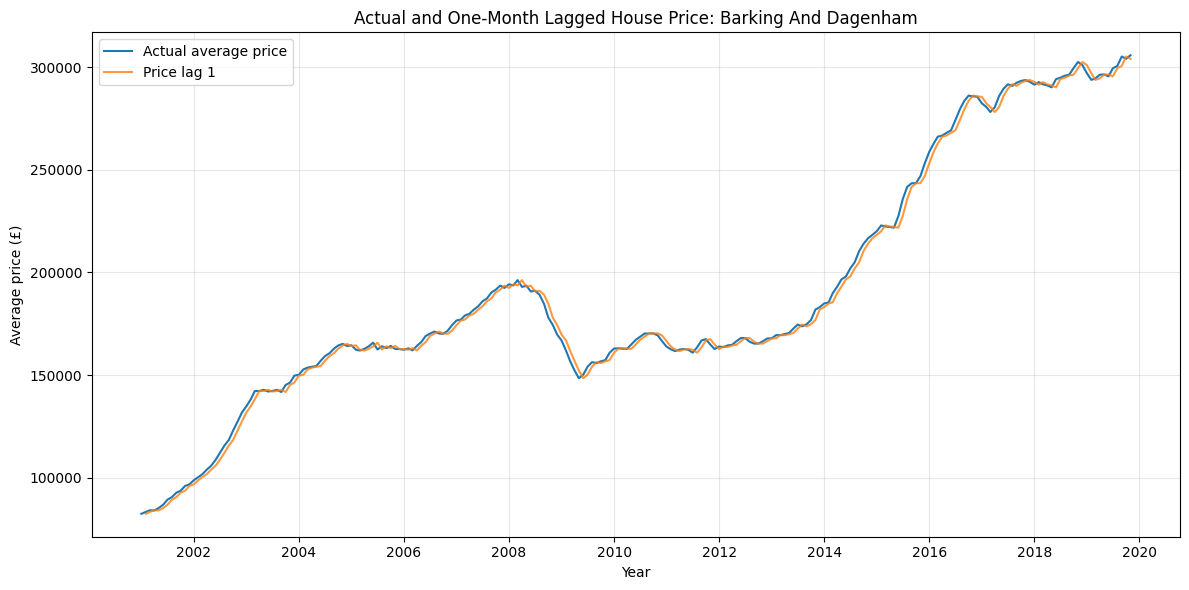

In [46]:
sample = df[df['area'] == sample_area].copy()

plt.figure(figsize=(12, 6))

plt.plot(
    sample['date'],
    sample['average_price'],
    label='Actual average price'
)

plt.plot(
    sample['date'],
    sample['price_lag_1'],
    label='Price lag 1',
    alpha=0.8
)

plt.title(
    f'Actual and One-Month Lagged House Price: {sample_area.title()}'
)
plt.xlabel('Year')
plt.ylabel('Average price (£)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The very close relationship between the two lines suggests that the previous month’s house price is a strong predictor of the current month’s price.


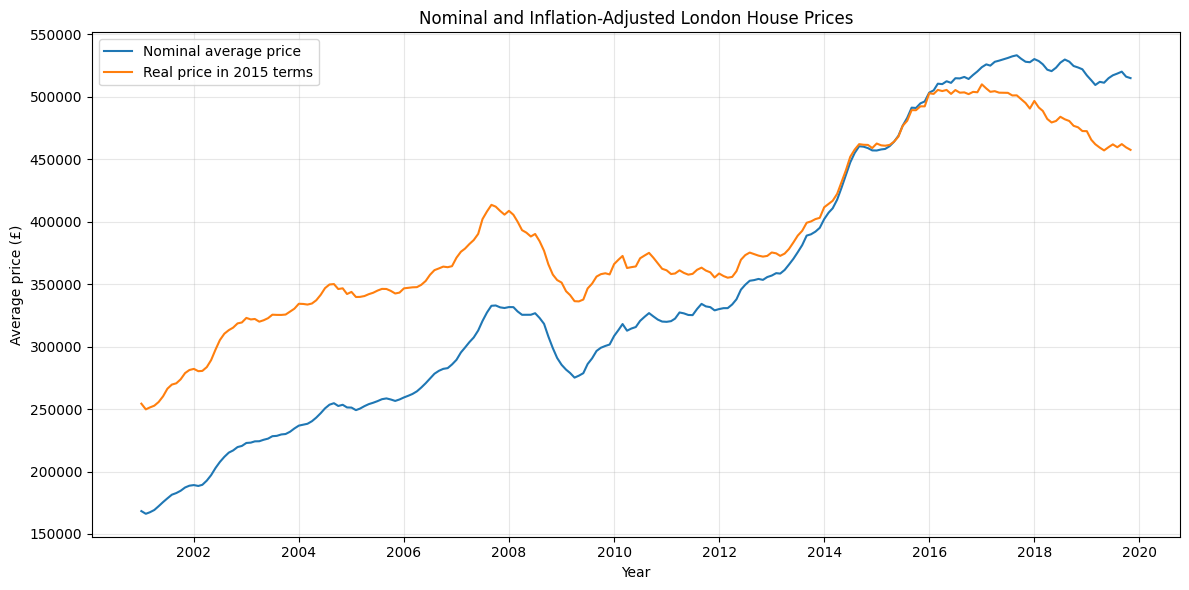

In [47]:
nominal_real = (
    df.groupby('date')[
        ['average_price', 'real_price_2015']
    ]
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    nominal_real.index,
    nominal_real['average_price'],
    label='Nominal average price'
)

plt.plot(
    nominal_real.index,
    nominal_real['real_price_2015'],
    label='Real price in 2015 terms'
)

plt.title('Nominal and Inflation-Adjusted London House Prices')
plt.xlabel('Year')
plt.ylabel('Average price (£)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



Nominal house prices represent the monetary value observed at each date, whereas real prices adjust those values using the Consumer Price Index with 2015 as the reference year. The comparison helps distinguish genuine growth in housing value from increases associated with general price inflation.

In [48]:
basic_features = [
    'year',
    'month_sin',
    'month_cos',
    'price_lag_1',
    'price_lag_12',
    'houses_sold_lag_1',
    'cpi_lag_1',
    'bank_rate_lag_1'
]

target = 'average_price'

In [49]:
extended_features = [
    'year',
    'quarter',
    'time_index',
    'month_sin',
    'month_cos',

    'price_lag_1',
    'price_lag_3',
    'price_lag_6',
    'price_lag_12',

    'price_rolling_mean_3',
    'price_rolling_mean_6',
    'price_rolling_mean_12',
    'price_rolling_std_12',

    'price_mom_growth_lag_1',
    'price_3m_growth_lag_1',
    'price_yoy_growth_lag_1',

    'houses_sold_lag_1',
    'houses_sold_lag_3',
    'houses_sold_lag_12',
    'houses_sold_rolling_mean_3',
    'houses_sold_rolling_mean_12',

    'cpi_lag_1',
    'cpi_lag_3',
    'cpi_lag_12',

    'bank_rate_lag_1',
    'bank_rate_lag_3',
    'bank_rate_lag_12',
    'bank_rate_change_1m_lag_1',

    'post_2008'
]

In [ ]:
#Build basic modelling dataset
model_columns = (
    ['date', 'area', target]
    + basic_features
)

df_model_basic = (
    df[model_columns]
    .dropna()
    .sort_values(['date', 'area'])
    .reset_index(drop=True)
)

print("Original rows:", len(df))
print("Basic modelling rows:", len(df_model_basic))

display(df_model_basic.head())

Original rows: 7375
Basic modelling rows: 6979


,date,area,average_price,year,month_sin,month_cos,price_lag_1,price_lag_12,houses_sold_lag_1,cpi_lag_1,bank_rate_lag_1
0,2002-01-01,barking and dagenham,98713,2002,0.500,0.866,"96,712.000","82,343.000",247.000,67.071,4.000
1,2002-01-01,barnet,203249,2002,0.500,0.866,"200,792.000","175,475.000",467.000,67.071,4.000
2,2002-01-01,bexley,124283,2002,0.500,0.866,"122,434.000","111,194.000",466.000,67.071,4.000
3,2002-01-01,brent,168671,2002,0.500,0.866,"165,833.000","148,306.000",341.000,67.071,4.000
4,2002-01-01,bromley,173150,2002,0.500,0.866,"172,583.000","153,615.000",567.000,67.071,4.000


In [51]:
extended_model_columns = (
    ['date', 'area', target]
    + extended_features
)

df_model_extended = (
    df[extended_model_columns]
    .dropna()
    .sort_values(['date', 'area'])
    .reset_index(drop=True)
)

print("Extended modelling rows:", len(df_model_extended))

display(df_model_extended.head())

Extended modelling rows: 6946


,date,area,average_price,year,quarter,time_index,month_sin,month_cos,price_lag_1,price_lag_3,price_lag_6,price_lag_12,price_rolling_mean_3,price_rolling_mean_6,price_rolling_mean_12,price_rolling_std_12,price_mom_growth_lag_1,price_3m_growth_lag_1,price_yoy_growth_lag_1,houses_sold_lag_1,houses_sold_lag_3,houses_sold_lag_12,houses_sold_rolling_mean_3,houses_sold_rolling_mean_12,cpi_lag_1,cpi_lag_3,cpi_lag_12,bank_rate_lag_1,bank_rate_lag_3,bank_rate_lag_12,bank_rate_change_1m_lag_1,post_2008
0,2002-02-01,barking and dagenham,100229,2002,1,14,0.866,0.500,"98,713.000","95,918.000","90,462.000","83,266.000","97,114.333","94,666.500","90,028.167","5,460.863",2.069,5.481,19.880,216.000,282.000,238.000,248.333,267.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
1,2002-02-01,barnet,202713,2002,1,14,0.866,0.500,"203,249.000","198,610.000","187,691.000","178,108.000","200,883.667","195,936.000","187,877.833","9,465.678",1.224,4.595,15.828,501.000,581.000,388.000,516.333,571.167,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
2,2002-02-01,bexley,124611,2002,1,14,0.866,0.500,"124,283.000","123,381.000","119,312.000","111,439.000","123,366.000","122,091.667","117,617.833","5,006.182",1.510,1.954,11.771,319.000,540.000,331.000,441.667,435.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
3,2002-02-01,brent,171147,2002,1,14,0.866,0.500,"168,671.000","163,992.000","160,832.000","150,110.000","166,165.333","164,464.000","158,984.417","6,345.480",1.711,2.650,13.732,315.000,430.000,297.000,362.000,394.500,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
4,2002-02-01,bromley,172833,2002,1,14,0.866,0.500,"173,150.000","170,870.000","164,849.000","154,097.000","172,201.000","169,790.167","163,759.750","6,960.504",0.329,1.731,12.717,445.000,681.000,410.000,564.333,630.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0


### Final leakage check

In [52]:
leakage_columns = [
    'average_price',
    'real_price_2015',
    'price_mom_growth_pct',
    'price_3m_growth_pct',
    'price_yoy_growth_pct'
]

for column in leakage_columns:
    if column in basic_features:
        print("Potential leakage in basic features:", column)

    if column in extended_features:
        print("Potential leakage in extended features:", column)

In [53]:
print(
    "Dates sorted:",
    df_model_basic['date'].is_monotonic_increasing
)

Dates sorted: True


In [54]:
df.to_csv(
    'london_housing_feature_engineered.csv',
    index=False
)

In [55]:
df_model_basic.to_csv(
    'london_housing_model_basic.csv',
    index=False
)

In [56]:
df_model_extended.to_csv(
    'london_housing_model_extended.csv',
    index=False
)

In [57]:
print("Files exported successfully:")
print("- london_housing_feature_engineered.csv")
print("- london_housing_model_basic.csv")
print("- london_housing_model_extended.csv")

Files exported successfully:
- london_housing_feature_engineered.csv
- london_housing_model_basic.csv
- london_housing_model_extended.csv




The feature engineering was done independently for each of the London areas and then by chronological order. The engineered variables comprised calendar features, cyclical month encoding, historical house price lags, rolling averages, rolling volatility, lags of market activity, historical growth rates, lags of CPI and Bank Rate, and inflation-adjusted house prices.

Lag predictors and rolling predictors were created based on the data preceding the target month to minimize the possibility for leakage. In particular, one month was added to the rolling features before calculating the rolling.

Two datasets for modelling were created. The basic dataset consists of a few reliable predictors for the first baseline and Linear Regression model. Later Random Forest and Gradient Boosting experiments use the extended data set, which includes extra lag, rolling, growth and macroeconomic characteristics.

It was anticipated that missing values would occur at the start of each area's time series as a result of lagging and rolling operations. These observations were not removed during the preparation of the final modelling datasets, but only during the preparation of the engineered datasets.